<div style="text-align: center;">
<h1>Comparing BattleActs’ Exam Preparation Samples</h1>
<h3>DATASCI 530 — Project 2</h3>
<p>Maxine Hakimi-Bulson</p>
</div>

## Introduction

BattleActs provides study materials for actuarial candidates preparing for Casualty Actuarial Society (CAS) exams. This project builds on my Project 1 collection of six exam preparation courses, nine public PDF samples, and six Excel workbooks collected from the BattleActs website on October 19, 2026. BattleActs granted written permission for the one-time educational collection.

The question this project aims to answer is: **How do BattleActs’ public samples differ across exams in their length, frequent terminology, and shared vocabulary?** In this report I compare the same type of sample materials across different exams and explore common terminology used, text length variation, and the most frequent terms mentioned with respect to each exam.

### Key Findings

- Study-manual samples are available for all six exams, ranging from approximately 2,100 to 6,500 words after cleaning.
- Study-manual samples mention different phrases based on the exam: Exam 5 samples mention “increased limits” frequently, Exam 6U samples mention “residual market” often, and “structured finance” is stated in Exam 9.
- Exams 5 and 7 have the highest manual vocabulary overlap, sharing 23.1% of their combined distinct vocabulary.
- Formula-summary samples are available for three exams and workbooks for five. Exam 9 provides only a study-manual sample among the PDF and Excel materials collected; videos were excluded.

In [1]:
# Import packages, load the Project 1 CSVs, and set the output folder.
# Define consistent formatting for the tables and figures.
from pathlib import Path
from collections import Counter
import csv
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader
from openpyxl import load_workbook
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from IPython.display import display, HTML

DATA_DIR = Path(".")
SAMPLE_DIR = DATA_DIR / "sample_files"
OUTPUT_DIR = DATA_DIR / "project2_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

products_final = pd.read_csv(DATA_DIR / "battleacts_products.csv")
pdf_samples = pd.read_csv(DATA_DIR / "battleacts_pdf_samples.csv")
excel_samples = pd.read_csv(DATA_DIR / "battleacts_excel_samples.csv")

exam_order = products_final["product_name"].tolist()

colors = [
    "#245B78", "#2A7F83", "#638A58",
    "#AE783B", "#76629A", "#AA5664"
]
exam_colors = dict(zip(exam_order, colors))

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110
})

display(HTML("""
<style>
.report-table {
    border-collapse: collapse;
    margin: 16px auto;
    font-size: 14px;
}
.report-table th, .report-table td {
    padding: 9px 12px;
    text-align: center !important;
    border-bottom: 1px solid #dce3e7;
}
.report-table th {
    background-color: #245B78;
    color: white;
}
.report-table tbody tr:nth-child(even) {
    background-color: #f3f7f9;
}
.output_png img, .jp-OutputArea-output img {
    max-width: 100%;
    height: auto;
}
</style>
"""))

def show_table(frame, formats=None):
    display(HTML(frame.to_html(
        index=False,
        classes="report-table",
        border=0,
        na_rep="—",
        formatters=formats
    )))

## Project 1 Revisions

This project imports the saved Project 1 datasets and processes the previously downloaded sample files.

Project 1 feedback mentioned issues with viewing the data in the CSV files. Text was found to be appearing in incorrect cells when the submitted CSVs were opened in Microsoft Excel. Several extracted text fields exceeded Excel’s limit of 32,767 characters per cell, although the CSVs loaded with the expected structure in Python and in Numbers.

To address these issues, the analysis uses the downloaded sample materials in their original PDF and Excel files rather than the CSV created in Project 1. PDF text is now organized by page, and workbook text is now separated by worksheet. Spreadsheet formulas and numeric spreadsheet cells are excluded from analysis since we want to explore relationships or find patterns between the words and phrases in the samples rather than calculated answers. The exported text fields are checked for excessive length, and each CSV is examined and opened in Excel to confirm that its rows, columns, and text are preserved.

In [2]:
# Identify each sample's material type and local file path.
# Combine file metadata without using the old extracted_text columns.
metadata_columns = [
    "product_name", "sample_label", "sample_url", "product_url",
    "collection_date", "content_collection_date"
]

pdf_inventory = pdf_samples[
    metadata_columns + ["page_count"]
].copy()
pdf_inventory["file_type"] = "PDF"

excel_inventory = excel_samples[
    metadata_columns + ["sheet_count", "formula_cells"]
].copy()
excel_inventory["file_type"] = "Excel"

inventory = pd.concat(
    [pdf_inventory, excel_inventory],
    ignore_index=True
)

def identify_file(row):
    label = row["sample_label"].lower()

    if row["file_type"] == "PDF":
        if "study manual" in label:
            return "Study manual", "Study_manual.pdf"
        return "Formula summary", "Formula_summary_sheet.pdf"

    if "past cas exams" in label:
        return "Workbook", "Past_CAS_exams.xlsx"

    return "Workbook", "Practice_problems_and_exams.xlsx"

file_details = inventory.apply(identify_file, axis=1)
inventory["material"] = file_details.map(lambda value: value[0])
inventory["filename"] = file_details.map(lambda value: value[1])

inventory["exam_folder"] = inventory["product_name"].str.replace(
    r"[^A-Za-z0-9]+", "_", regex=True
).str.strip("_")

inventory["local_path"] = inventory.apply(
    lambda row: (
        SAMPLE_DIR
        / row["file_type"]
        / row["exam_folder"]
        / row["filename"]
    ),
    axis=1
)

missing_files = [
    str(path) for path in inventory["local_path"]
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Check these sample file locations:\n" + "\n".join(missing_files)
    )

# Confirm that file records are unique and linked to known products.
assert products_final["product_url"].is_unique
assert inventory["sample_url"].is_unique
assert inventory["product_url"].isin(
    products_final["product_url"]
).all()

## Extracting Readable Sample Content

Each PDF page and Excel worksheet becomes a separate record linked to its exam and source URL. Page counts, worksheet counts, and formula counts are compared with the Project 1 metadata. Workbook cells containing formulas are excluded from the extracted narrative text. Text from instruction sheets, contents sheets, and score grids is kept in the dataset but is not used in the text analysis. This approach preserves the original files for reference while producing smaller text records that are easier to inspect and analyze.

In [3]:
# Extract text by PDF page and Excel worksheet, excluding formula cells.
admin_sheets = {
    "instructions", "point grid", "toc",
    "contents", "table of contents"
}

source_columns = [
    "product_name", "sample_url", "product_url",
    "collection_date", "content_collection_date",
    "file_type", "material"
]

records = []

for _, file in inventory.iterrows():
    common = {column: file[column] for column in source_columns}

    if file["file_type"] == "PDF":
        reader = PdfReader(file["local_path"])

        assert len(reader.pages) == int(file["page_count"])

        for page_number, page in enumerate(reader.pages, start=1):
            records.append({
                **common,
                "unit": str(page_number),
                "included": True,
                "formula_cells": 0,
                "raw_text": page.extract_text() or ""
            })

    else:
        book = load_workbook(
            file["local_path"],
            read_only=True,
            data_only=False
        )

        try:
            assert len(book.sheetnames) == int(file["sheet_count"])
            total_formulas = 0

            for sheet in book.worksheets:
                blocks = []
                formulas = 0

                for row in sheet.iter_rows():
                    for cell in row:
                        if cell.data_type == "f":
                            formulas += 1

                        elif (
                            isinstance(cell.value, str)
                            and re.search(r"[A-Za-z]", cell.value)
                        ):
                            blocks.append(cell.value.strip())

                total_formulas += formulas

                records.append({
                    **common,
                    "unit": sheet.title,
                    "included": (
                        sheet.title.strip().lower() not in admin_sheets
                    ),
                    "formula_cells": formulas,
                    "raw_text": "\n".join(blocks)
                })

            assert total_formulas == int(file["formula_cells"])

        finally:
            book.close()

segments = pd.DataFrame(records)

# Check that every expected page and worksheet was processed.
assert segments["sample_url"].nunique() == len(inventory)

assert segments["file_type"].eq("PDF").sum() == int(
    pdf_samples["page_count"].sum()
)

assert segments["file_type"].eq("Excel").sum() == int(
    excel_samples["sheet_count"].sum()
)

assert not segments.duplicated(["sample_url", "unit"]).any()

assert not segments["raw_text"].str.contains(
    "object at 0x", regex=False
).any()

## Preparing Text for Comparison

Lines containing website addresses, navigation links, or footer text are removed. Common English stopwords and recurring document labels are excluded from vocabulary summaries. Two-word phrases are counted only when the words were adjacent within the same text line and sentence. Counts are case-insensitive. Selected singular and plural phrase variants are combined for the phrase charts, and individual word forms remain separate in the vocabulary-similarity analysis.

In [4]:
# Remove identifiable navigation text and define vocabulary-counting rules.
# Count adjacent word pairs before excluding stopwords to avoid artificial phrases.
noise = re.compile(
    r"https?://|www\.|battleacts\d*\.ca|retrieved from|last edited"
    r"|return to (?:toc|point grid)|mini battlequiz|full battlequiz"
    r"|must be logged in|click for answer|^\s*\d+/\d+\s*$",
    re.I
)

def clean_text(text):
    lines = []

    for line in text.splitlines():
        if not noise.search(line):
            lines.append(re.sub(r"\s+", " ", line).strip())

    return "\n".join(line for line in lines if line)

segments["analysis_text"] = segments["raw_text"].map(clean_text)

document_labels = set("""
battleacts battlequiz battlecards wiki pdf worksheet
question questions answer answers problem problems
example examples calculate calculation following given
reading synopsis study tips plain english contents
return point grid points available achieved incomplete
complete werner sneak peek article sample
""".split())

stopwords = set(ENGLISH_STOP_WORDS) | document_labels

# Exclude generic phrases and repeated-word pairs from phrase summaries.
excluded_phrases = {"web based", "source text"}

def tokens(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

def useful_word(word):
    return len(word) >= 3 and word not in stopwords

def count_terms(text):
    word_counts = Counter()
    phrase_counts = Counter()
    total_words = 0

    for line in text.splitlines():
        for sentence in re.split(r"[.!?;]", line):
            sequence = tokens(sentence)
            total_words += len(sequence)

            word_counts.update(
                word for word in sequence if useful_word(word)
            )

            for first, second in zip(sequence, sequence[1:]):
                phrase = first + " " + second

                if (
                    useful_word(first)
                    and useful_word(second)
                    and first != second
                    and phrase not in excluded_phrases
                ):
                    phrase_counts[phrase] += 1

    return total_words, word_counts, phrase_counts

segments["word_count"] = segments["analysis_text"].map(
    lambda text: len(tokens(text))
)

### Comparing Samples of Different Lengths

Text is grouped by exam and sample material category. Word counts describe the cleaned text, prior to removing any stopwords. Frequent phrases are reported as occurrences per 1,000 words, so that longer samples do not automatically receive higher frequencies or importance.

In [5]:
# Combine eligible text by exam and material type.
# Calculate word totals and word and phrase frequencies for each group.
analysis_segments = segments[segments["included"]].copy()

stats = {}

for (exam, material), group in analysis_segments.groupby(
    ["product_name", "material"],
    sort=False
):
    text = "\n".join(group["analysis_text"])
    total_words, word_counts, phrase_counts = count_terms(text)

    stats[(exam, material)] = {
        "word_count": total_words,
        "words": word_counts,
        "phrases": phrase_counts
    }

# Confirm that each exam has usable manual text.
assert all(
    stats[(exam, "Study manual")]["word_count"] > 0
    for exam in exam_order
)

## Results

### Summary Statistics

Recall the summary statistics of the exam courses found in Project 1:

In [12]:
# Calculate course counts, mean prices, and sample variances by currency.
price_summary = (
    products_final.groupby("currency", sort=False)["price"]
    .agg(["count", "mean", "var"])
    .reset_index()
    .rename(columns={
        "currency": "Currency",
        "count": "Courses (n)",
        "mean": "Mean listed price",
        "var": "Sample variance"
    })
)

show_table(price_summary, {
    "Mean listed price": "{:,.2f}".format,
    "Sample variance": "{:,.2f}".format
})

Currency,Courses (n),Mean listed price,Sample variance
USD,5,900.00,"50,000.00"
CAD,1,"1,000.00",—


Five courses are priced in USD, with a mean listed price of $900 and a sample variance of 50,000 USD². Exam 6C is priced separately at CAD 1,000, and its sample variance is undefined since there is only one course that uses that currency. 

### Table 1. Courses and Public Sample Availability

The table summarizes all six courses and the unique PDF and Excel files collected for each exam. Sample counts refer to downloaded files, while practice-exam counts refer to the number advertised in each course’s feature list.

In [6]:
# Summarize course prices, access periods, and advertised practice exams.
# Count unique PDF and Excel samples for each course.
overview = products_final[[
    "product_name", "price", "currency",
    "duration_months", "practice_exam_count"
]].copy()

overview["Listed price"] = overview.apply(
    lambda row: f'{row["price"]:,.0f} {row["currency"]}',
    axis=1
)

overview["PDF files"] = overview["product_name"].map(
    inventory[inventory["file_type"].eq("PDF")]
    .groupby("product_name").size()
).fillna(0).astype(int)

overview["Excel files"] = overview["product_name"].map(
    inventory[inventory["file_type"].eq("Excel")]
    .groupby("product_name").size()
).fillna(0).astype(int)

overview = overview.rename(columns={
    "product_name": "Exam prep course",
    "duration_months": "Access (months)",
    "practice_exam_count": "Advertised original practice exams"
})

overview = overview[[
    "Exam prep course", "Listed price", "Access (months)",
    "Advertised original practice exams", "PDF files", "Excel files"
]]

show_table(overview)

Exam prep course,Listed price,Access (months),Advertised original practice exams,PDF files,Excel files
CAS Exam 5,500 USD,7,4,2,1
CAS Exam 6C,"1,000 CAD",7,1,1,1
CAS Exam 6U,"1,000 USD",7,2,2,2
CAS Exam 7,"1,000 USD",7,2,2,1
CAS Exam 8,"1,000 USD",7,2,1,1
CAS Exam 9,"1,000 USD",7,2,1,0


All courses advertise seven months of access and a conditional, one-time six-month extension. All exams provide a manual sample. Exams 5, 6U, and 7 offer formula-summary PDF samples. Exam 9 is the only exam without an Excel workbook sample available. Two Exam 5 sample buttons linked to the same PDF, so this is only counted once.

### Table 2. Readable Text Available for Analysis

Word counts are calculated after removing navigation and footer text. Workbook counts exclude administrative worksheets and formula cells. A dash indicates the sample type was unavailable.

In [7]:
# Compare word totals by material type and count eligible workbook worksheets.
# Leave unavailable material categories with a dash
rows = []

for exam in exam_order:
    row = {"Exam": exam}

    for material, column in [
        ("Study manual", "Manual words"),
        ("Formula summary", "Formula-summary words"),
        ("Workbook", "Workbook words")
    ]:
        result = stats.get((exam, material))
        row[column] = (
            result["word_count"] if result is not None else np.nan
        )

    workbook_units = analysis_segments[
        analysis_segments["product_name"].eq(exam)
        & analysis_segments["file_type"].eq("Excel")
    ]

    row["Worksheets analyzed"] = (
        len(workbook_units) if len(workbook_units) else np.nan
    )

    rows.append(row)

text_summary = pd.DataFrame(rows)

show_table(
    text_summary,
    {
        column: "{:,.0f}".format
        for column in text_summary.columns
        if column != "Exam"
    }
)

Exam,Manual words,Formula-summary words,Workbook words,Worksheets analyzed
CAS Exam 5,"6,530",711,"2,441",30
CAS Exam 6C,"3,252",—,"2,250",10
CAS Exam 6U,"2,090",715,"2,958",29
CAS Exam 7,"3,604","1,054",919,3
CAS Exam 8,"2,903",—,"4,088",15
CAS Exam 9,"4,029",—,—,—


Across the six workbooks, 95 worksheets were extracted, and 87 remained after removing administrative worksheets. The manual samples range from approximately 2,000 to 6,500 readable words with Exam 5 having the longest manual sample (6,530 words), and Exam 6U having the shortest (2,090 words). Formula summaries also differ in length and layout. Their text counts describe extracted terminology, not counts of mathematical formulas. Among the PDF and Excel materials collected from BattleActs, Exam 9 only has a study-manual sample.

### Figure 1. Frequent Phrases in Study-Manual Samples

Each panel shows the five most frequent eligible two-word phrases in one study-manual sample. All panels use the same horizontal scale, measured in occurrences per 1,000 words. Selected singular and plural variants were combined to avoid displaying the same phrase twice among the top five.

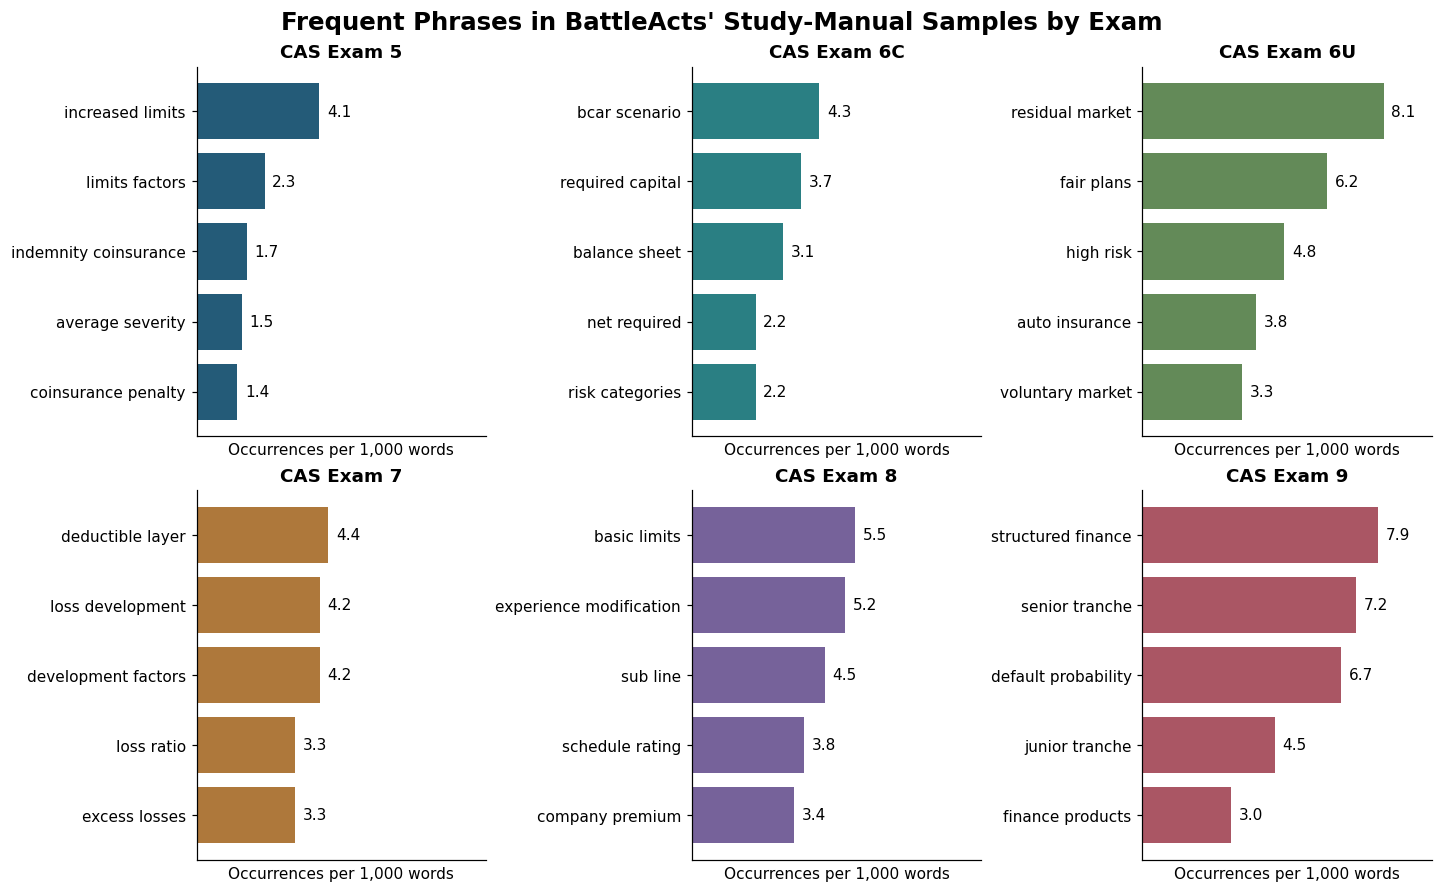

In [17]:
# Plot each exam's five most frequent phrases per 1,000 words.

# Combine specified singular/plural variants for phrase charts only.
phrase_aliases = {
    "residual markets": "residual market",
    "senior tranches": "senior tranche",
    "junior tranches": "junior tranche",
    "default probabilities": "default probability"
}

def combined_phrases(phrase_counts):
    combined = Counter()

    for phrase, count in phrase_counts.items():
        label = phrase_aliases.get(phrase, phrase)
        combined[label] += count

    return combined
def phrase_panels(material, title):
    available = [
        exam for exam in exam_order
        if (exam, material) in stats
    ]
    fig, axes = plt.subplots(
        2, 3,
        figsize=(13, 8),
        layout="constrained"
    )
    for ax in axes.flat:
        ax.set_visible(False)

    maximum = max(
        (
            1000 * count / stats[(exam, material)]["word_count"]
            for exam in available
            for phrase, count in
            combined_phrases(stats[(exam, material)]["phrases"]).most_common(5)
        ),
        default=1
    )
    for ax, exam in zip(axes.flat, available):
        ax.set_visible(True)

        result = stats[(exam, material)]
        top = combined_phrases(result["phrases"]).most_common(5)

        phrases = [phrase for phrase, count in top]
        frequencies = [
            1000 * count / result["word_count"]
            for phrase, count in top
        ]

        bars = ax.barh(
            phrases,
            frequencies,
            color=exam_colors[exam]
        )

        # Label bar values and remove gridlines and x-axis ticks.
        ax.bar_label(bars, fmt="%.1f", padding=5)
        ax.grid(False)
        ax.set_xticks([])

        ax.invert_yaxis()
        ax.set_xlim(0, maximum * 1.20)
        ax.set_title(exam, fontweight="bold")
        ax.set_xlabel("Occurrences per 1,000 words")

    fig.suptitle(title, fontsize=16, fontweight="bold")
    plt.show()

phrase_panels(
    "Study manual",
    "Frequent Phrases in BattleActs' Study-Manual Samples by Exam"
)

The most frequent phrases show differences in the subjects discussed in each study-manual sample:

- **Exam 5:** “Increased limits” leads at 4.1 occurrences per 1,000 words. Other frequent phrases relate to coinsurance and loss severity, suggesting an emphasis on insurance limits and loss calculations.
- **Exam 6C:** “BCAR scenario” (4.3), “required capital” (3.7), and “balance sheet” (3.1) suggest a focus on capital assessment and insurers’ financial positions.
- **Exam 6U:** After combining singular and plural forms, “residual market” leads at 8.1 occurrences per 1,000 words. Together with “FAIR plans,” “high risk,” and “voluntary market,” these phrases suggest discussion of insurance availability and different insurance markets.
- **Exam 7:** “Deductible layer” (4.4), “loss development” (4.2), and “development factors” (4.2) suggest an emphasis on loss development and the treatment of losses within different layers.
- **Exam 8:** “Basic limits” (5.5) and “experience modification” (5.2), alongside “schedule rating” and “company premium,” suggest a focus on insurance pricing and rating methods.
- **Exam 9:** “Structured finance” (7.9), “senior tranche” (7.2), and “default probability” (6.7) suggest an emphasis on structured financial products and default risk.

Exams 6U and 9 have particularly prominent leading phrases. The top phrases in Exam 7 have similar counts.

### Figure 2. Shared Vocabulary Between Manual Samples

Jaccard similarity measures the proportion of distinct cleaned words shared by two samples out of all distinct words appearing in either sample. The calculation uses words of at least three letters after stopword and document-label removal and compares terminology only.

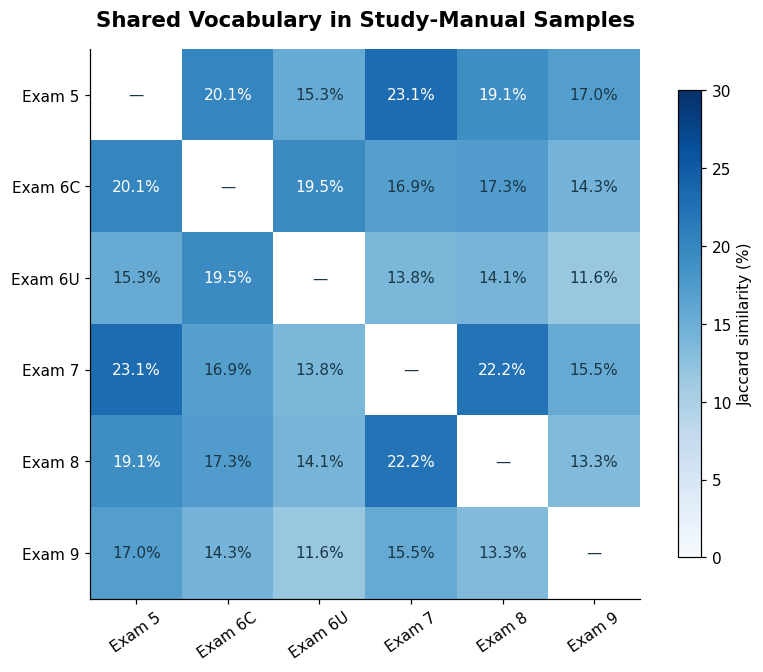

In [23]:
# Calculate shared distinct vocabulary using Jaccard similarity.
manual_vocabulary = {
    exam: set(stats[(exam, "Study manual")]["words"])
    for exam in exam_order
}

similarity = pd.DataFrame(
    index=exam_order,
    columns=exam_order,
    dtype=float
)

for first in exam_order:
    for second in exam_order:
        shared = (
            manual_vocabulary[first]
            & manual_vocabulary[second]
        )
        combined = (
            manual_vocabulary[first]
            | manual_vocabulary[second]
        )

        similarity.loc[first, second] = (
            100 * len(shared) / len(combined)
            if combined else np.nan
        )

# Omit self-comparisons from the figure.
heatmap_values = similarity.to_numpy().copy()
np.fill_diagonal(heatmap_values, np.nan)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")

image = ax.imshow(
    np.ma.masked_invalid(heatmap_values),
    cmap="Blues",
    vmin=0,
    vmax=30
)

short_labels = [
    exam.replace("CAS ", "") for exam in exam_order
]

ax.set_xticks(range(len(exam_order)), short_labels, rotation=35)
ax.set_yticks(range(len(exam_order)), short_labels)

for row in range(len(exam_order)):
    for column in range(len(exam_order)):
        value = heatmap_values[row, column]

        ax.text(
            column,
            row,
            "—" if np.isnan(value) else f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value > 18 else "#193746"
        )

ax.set_title(
    "Shared Vocabulary in Study-Manual Samples",
    fontsize=14,
    fontweight="bold",
    pad=15
)

colorbar = fig.colorbar(image, ax=ax, shrink=0.85)
colorbar.set_label("Jaccard similarity (%)")

plt.show()

Exams 5 and 7 have the highest manual vocabulary similarity (23.1%), followed by Exams 7 and 8 (22.2%), consistent with shared terminology involving losses, development, and insurance calculations. I initially expected Exams 6C and 6U to share more vocabulary because they are regional versions of Exam 6, but their similarity is 19.5%. However, their samples focus on different subjects: 6C focuses on capital assessment while 6U discusses residual insurance markets. Thus, the figure may reflect only diction differences between the study-manual samples rather than differences between the full courses.

### Figure 3. Frequent Phrases in Workbook Samples

The workbook comparison uses readable text from the non-administrative worksheets. Formula expressions and numbers are excluded. The two Exam 6U workbooks are combined for this analysis. Exam 9 is not included since there is no sample workbook available on the website.

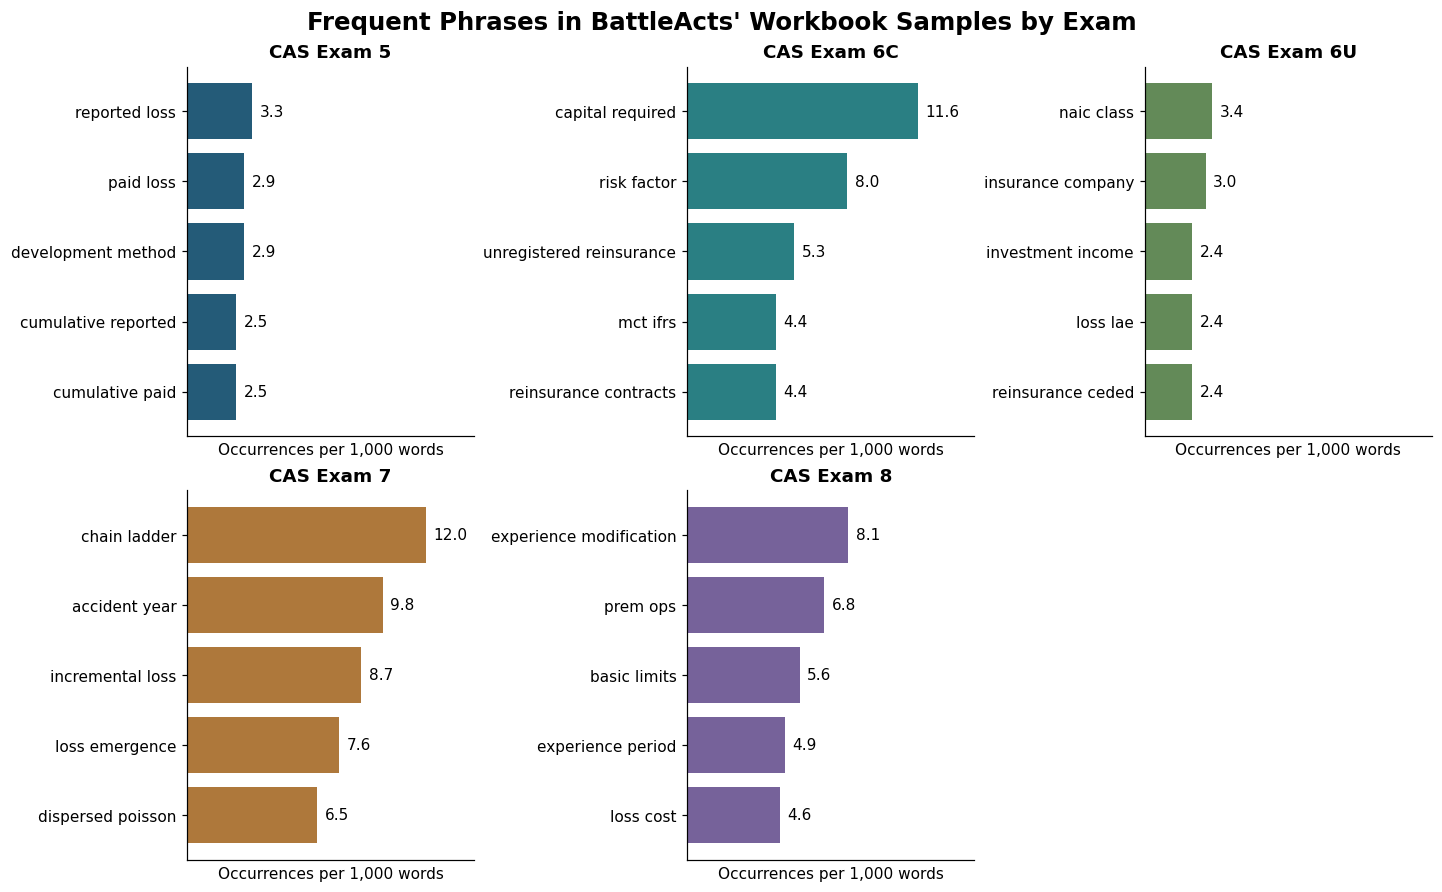

In [21]:
# Apply the phrase chart function to eligible workbook text.
phrase_panels(
    "Workbook",
    "Frequent Phrases in BattleActs' Workbook Samples by Exam"
)

The workbook samples also show differences in frequently used terminology across exams:

- **Exam 5:** “Reported loss” leads at 3.3 occurrences per 1,000 words, followed by “paid loss” and “development method” at 2.9 each. These phrases suggest practice involving loss amounts and development calculations.
- **Exam 6C:** “Capital required” (11.6) appears more frequently than the other leading phrases. Together with “risk factor” (8.0) and “unregistered reinsurance” (5.3), this suggests an emphasis on capital requirements and related insurance risks.
- **Exam 6U:** “NAIC class” (3.4) and “insurance company” (3.0) lead, followed by terms involving investment income, losses, and reinsurance. These results combine two workbooks, so they reflect the pooled samples rather than one practice document.
- **Exam 7:** “Chain ladder” leads at 12.0 occurrences per 1,000 words—the highest displayed phrase frequency across the workbook samples. “Accident year,” “incremental loss,” and “loss emergence” also suggest a focus on loss-development methods.
- **Exam 8:** “Experience modification” (8.1), “basic limits” (5.6), and “loss cost” (4.6) suggest practice involving insurance rating and pricing. “Experience modification” and “basic limits” also appear among the leading manual phrases for Exam 8, connecting the terminology in its explanatory and practice samples.

The leading phrases in Exams 6C and 7 occur more frequently than those in Exams 5 and 6U, indicating greater repetition of these particular expressions per 1,000 words.

## Discussion

The public samples differ in both availability and terminology. Shared phrases such as “experience modification” and “basic limits” connect Exam 8’s manual and workbook samples, suggesting related explanatory and practice content. Exams 5 and 7 have the highest manual vocabulary overlap, although this describes the selected excerpts rather than the full courses.

For BattleActs, these findings could help communicate what students can expect from each sample material. The Exam 5 button referring to Excel that leads to a PDF should be fixed. Clearly separating publicly available samples from materials included in the paid course could help visitors understand what they can preview and what requires a purchase.

## Revised Datasets and Reproducibility

Three CSVs are exported: the product dataset, PDF text organized by page, and Excel text organized by worksheet. Formula expressions are excluded from the workbook text, and all exported text fields are below 30,000 characters. Each CSV is checked to ensure its structure and text are appearing correctly. The `word_count` column measures cleaned text before stopword removal, while `extracted_text` retains navigation and footer text removed during analysis.

In [11]:
# Export corrected page-level and worksheet-level datasets alongside products.
# Build page-level PDF records.
pdf_samples_clean = segments[
    segments["file_type"].eq("PDF")
].copy()

pdf_samples_clean["page_number"] = (
    pdf_samples_clean["unit"].astype(int)
)

pdf_samples_clean = pdf_samples_clean.rename(columns={
    "raw_text": "extracted_text"
})

pdf_samples_clean = pdf_samples_clean[[
    "product_name", "material", "sample_url", "product_url",
    "collection_date", "content_collection_date",
    "page_number", "extracted_text", "word_count"
]]

# Build worksheet-level Excel records.
excel_samples_clean = segments[
    segments["file_type"].eq("Excel")
].copy()

excel_samples_clean = excel_samples_clean.rename(columns={
    "unit": "worksheet",
    "included": "included_in_analysis",
    "raw_text": "extracted_text"
})

excel_samples_clean = excel_samples_clean[[
    "product_name", "sample_url", "product_url",
    "collection_date", "content_collection_date",
    "worksheet", "included_in_analysis",
    "formula_cells", "extracted_text", "word_count"
]]

# Standardize whitespace without shortening or truncating the text.
for frame in [pdf_samples_clean, excel_samples_clean]:
    frame["extracted_text"] = (
        frame["extracted_text"]
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    assert frame["extracted_text"].str.len().le(30000).all(), (
        "An oversized text record needs to be split before export."
    )

exports = {
    "battleacts_products.csv": products_final,
    "battleacts_pdf_samples.csv": pdf_samples_clean,
    "battleacts_excel_samples.csv": excel_samples_clean
}

for filename, frame in exports.items():
    path = OUTPUT_DIR / filename

    frame.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        quoting=csv.QUOTE_ALL
    )

    restored = pd.read_csv(path, keep_default_na=False)

    assert restored.shape == frame.shape
    assert restored.columns.tolist() == frame.columns.tolist()

    # Check all text columns, including URLs and timestamps.
    for column in frame.select_dtypes(include="object").columns:
        assert (
            restored[column].astype(str).tolist()
            == frame[column].fillna("").astype(str).tolist()
        )

## Source: BattleActs

BattleActs. Public product pages and linked PDF and Excel samples, collected October 19, 2026, with written permission for educational use.

Website: [BattleActs](https://battleactsmain.ca/v2/home)